# 02 - Exploratory data analysis

First look at the **cleaned** Sepsis event log: how many cases, which activities, how long pathways are and how they end.

Charts are saved to `reports/figures/` for the report and slides.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
sys.path.append(str(Path.cwd().parent / 'src'))

from clean_data import load_clean_log
from load_data import CASE_ID, ACTIVITY, TIMESTAMP
from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY

apply_style()
log = load_clean_log()
log.shape

(14214, 32)

## 1. Cases at a glance

In [2]:
cases = log.groupby(CASE_ID).agg(
    start=(TIMESTAMP, 'min'),
    end=(TIMESTAMP, 'max'),
    events=(ACTIVITY, 'size'),
    age=('Age', 'first'),
)
cases['duration_days'] = (cases['end'] - cases['start']).dt.total_seconds() / 86400

pd.Series({
    'Cases': len(cases),
    'Events': len(log),
    'Distinct activities': log[ACTIVITY].nunique(),
    'First case starts': cases['start'].min().date(),
    'Last case starts': cases['start'].max().date(),
    'Median age': cases['age'].median(),
}, name='value').to_frame()

,value
Cases,995
Events,14214
Distinct activities,16
First case starts,2013-11-07
Last case starts,2015-02-25
Median age,75.0


### Chart 1 - Cases started per month

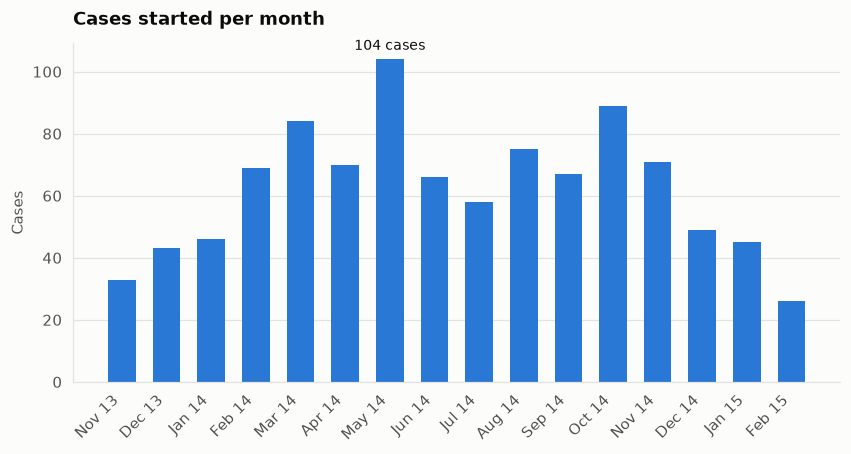

In [3]:
monthly = cases['start'].dt.tz_convert(None).dt.to_period('M').value_counts().sort_index()
labels = [p.strftime('%b %y') for p in monthly.index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, monthly.values, color=BLUE, width=0.62)
ax.grid(axis='x', visible=False)
peak = monthly.values.argmax()
ax.annotate(f'{monthly.values[peak]} cases', (peak, monthly.values[peak]),
            ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', color=INK, fontsize=9)
ax.set_title('Cases started per month')
ax.set_ylabel('Cases')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
save_fig(fig, 'eda_cases_per_month')
plt.show()

### Chart 2 - Activity frequency
Bar = number of events. Label also shows the share of cases in which the activity occurs at least once.

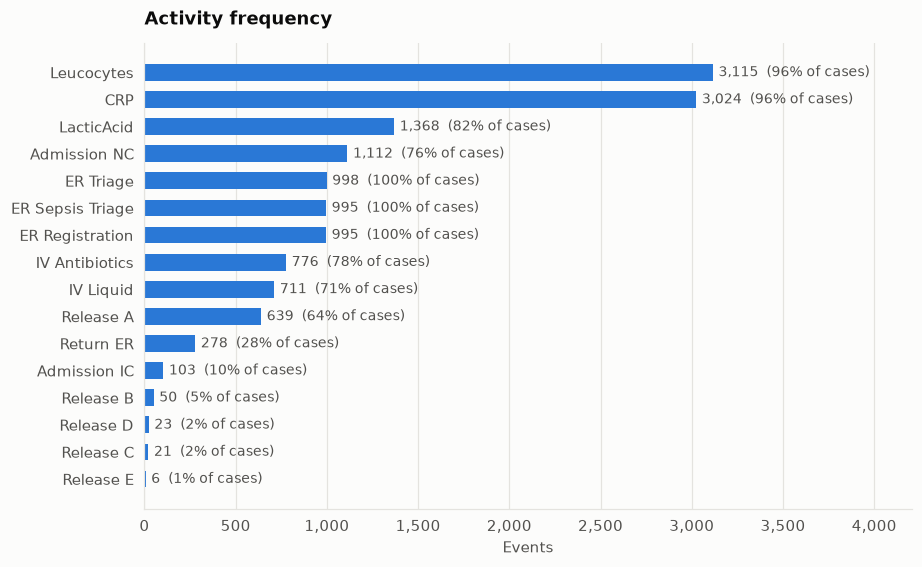

In [4]:
events_per_activity = log[ACTIVITY].value_counts()
case_share = log.groupby(ACTIVITY)[CASE_ID].nunique().div(len(cases)).mul(100)
order = events_per_activity.sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(order.index, order.values, color=BLUE, height=0.62)
ax.grid(axis='y', visible=False)
for i, (act, n) in enumerate(order.items()):
    ax.text(n + order.max() * 0.01, i, f'{n:,}  ({case_share[act]:.0f}% of cases)',
            va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, order.max() * 1.35)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_title('Activity frequency')
ax.set_xlabel('Events')
save_fig(fig, 'eda_activity_frequency')
plt.show()

### Chart 3 - Events per case

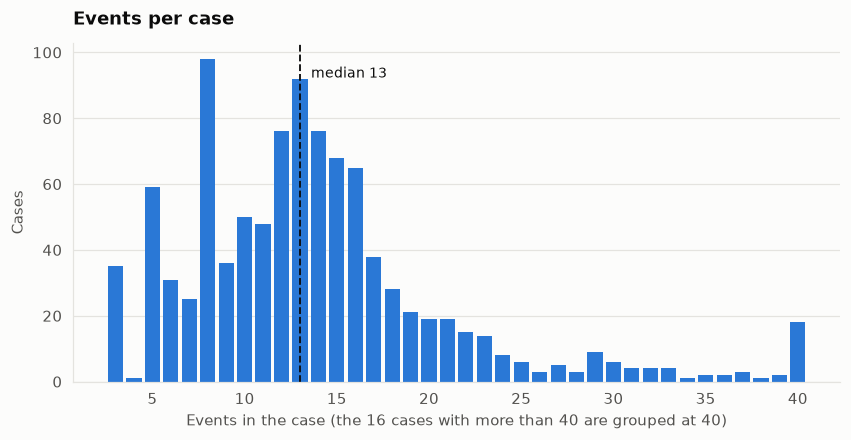

,events per case
count,995.0
mean,14.3
std,11.3
min,3.0
25%,8.5
50%,13.0
75%,16.0
max,184.0


In [5]:
CAP = 40
n_over = int((cases['events'] > CAP).sum())
median_events = cases['events'].median()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(cases['events'].clip(upper=CAP), bins=np.arange(2.5, CAP + 1.5, 1), color=BLUE, rwidth=0.82)
ax.axvline(median_events, color=INK, linewidth=1.2, linestyle='--')
ax.text(median_events + 0.6, ax.get_ylim()[1] * 0.93, f'median {median_events:.0f}', color=INK, fontsize=9, va='top')
ax.grid(axis='x', visible=False)
ax.set_title('Events per case')
ax.set_xlabel(f'Events in the case (the {n_over} cases with more than {CAP} are grouped at {CAP})')
ax.set_ylabel('Cases')
save_fig(fig, 'eda_events_per_case')
plt.show()
cases['events'].describe().round(1).to_frame('events per case')

### Chart 4 - Case duration
Time from the first to the last event of a case. Durations are very skewed, so the axis is logarithmic.

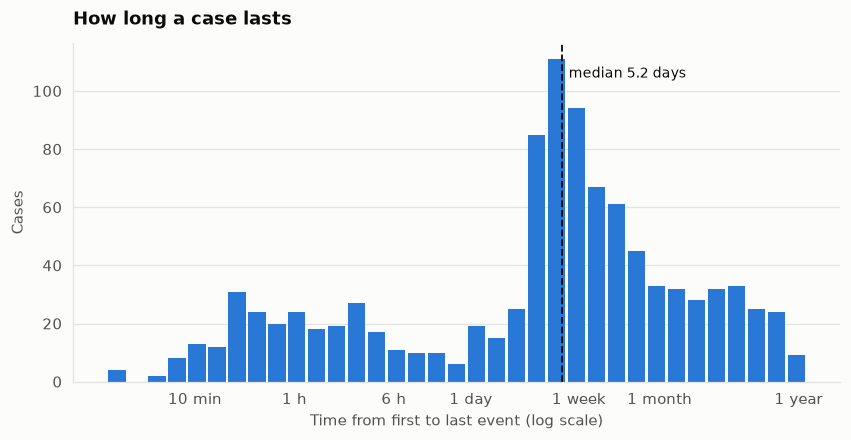

In [6]:
hours = cases['duration_days'] * 24
median_h = hours.median()
bins = np.logspace(np.log10(max(hours.min(), 0.02)), np.log10(hours.max()), 36)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(hours.clip(lower=bins[0]), bins=bins, color=BLUE, rwidth=0.88)
ax.set_xscale('log')
ticks = [1 / 6, 1, 6, 24, 24 * 7, 24 * 30, 24 * 365]
ax.set_xticks(ticks)
ax.set_xticklabels(['10 min', '1 h', '6 h', '1 day', '1 week', '1 month', '1 year'])
ax.minorticks_off()
ax.axvline(median_h, color=INK, linewidth=1.2, linestyle='--')
ax.text(median_h * 1.12, ax.get_ylim()[1] * 0.93, f'median {median_h / 24:.1f} days', color=INK, fontsize=9, va='top')
ax.grid(axis='x', visible=False)
ax.set_title('How long a case lasts')
ax.set_xlabel('Time from first to last event (log scale)')
ax.set_ylabel('Cases')
save_fig(fig, 'eda_case_duration')
plt.show()

In [7]:
d = cases['duration_days']
pd.Series({
    'Median (days)': d.median(),
    'Mean (days)': d.mean(),
    '90th percentile (days)': d.quantile(0.9),
    'Longest (days)': d.max(),
    'Cases under 1 day (%)': (d < 1).mean() * 100,
    'Cases under 7 days (%)': (d < 7).mean() * 100,
    'Cases over 30 days (%)': (d > 30).mean() * 100,
}, name='value').round(1).to_frame()

,value
Median (days),5.2
Mean (days),28.4
90th percentile (days),91.3
Longest (days),422.3
Cases under 1 day (%),26.0
Cases under 7 days (%),58.4
Cases over 30 days (%),19.5


### Chart 5 - How cases end
The first `Release` code in each case (A to E). Cases with no `Release` event have no recorded discharge.

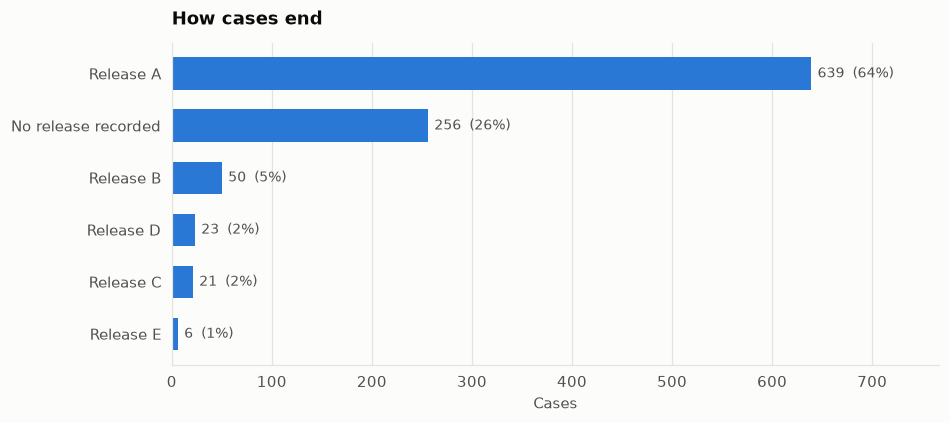

,median duration (days)
outcome,
No release recorded,0.0
Release B,4.5
Release A,9.0
Release C,15.8
Release D,18.2
Release E,25.3


In [8]:
outcome = (
    log[log[ACTIVITY].str.startswith('Release')]
    .groupby(CASE_ID)[ACTIVITY].first()
    .reindex(cases.index)
    .fillna('No release recorded')
)
counts = outcome.value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(counts.index, counts.values, color=BLUE, height=0.62)
ax.grid(axis='y', visible=False)
for i, n in enumerate(counts.values):
    ax.text(n + counts.max() * 0.01, i, f'{n}  ({n / len(cases) * 100:.0f}%)', va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, counts.max() * 1.2)
ax.set_title('How cases end')
ax.set_xlabel('Cases')
save_fig(fig, 'eda_case_outcomes')
plt.show()

cases['outcome'] = outcome
cases.groupby('outcome')['duration_days'].median().round(1).sort_values().to_frame('median duration (days)')

### Other quick checks

In [9]:
pd.DataFrame({
    'Cases that reach intensive care': [(log[ACTIVITY] == 'Admission IC').groupby(log[CASE_ID]).any().sum()],
    'Cases admitted to normal care': [(log[ACTIVITY] == 'Admission NC').groupby(log[CASE_ID]).any().sum()],
    'Cases that return to the ER': [(log[ACTIVITY] == 'Return ER').groupby(log[CASE_ID]).any().sum()],
}).T.rename(columns={0: 'cases'})

,cases
Cases that reach intensive care,98
Cases admitted to normal care,756
Cases that return to the ER,278


## Findings
- **Size:** 995 cases and 14,214 events across 16 activities. Cases start between Nov 2013 and Feb 2015, with a peak of 104 in May 2014. The first and last months are low, possibly because the log starts and ends part-way through them.
- **Standard entry steps:** `ER Registration`, `ER Triage` and `ER Sepsis Triage` occur in every case. Leucocyte and CRP tests occur in 96% of cases, lactic acid in 82%.
- **Treatment:** 78% of cases receive IV antibiotics and 71% IV fluids. 76% are admitted to a normal care ward and 10% to intensive care.
- **Pathway length:** the median case has 13 events (90th percentile 22). A few cases are extreme (16 have more than 40 events, the longest 184), so these should be checked as possible outliers or repeated lab tests.
- **Duration is very uneven:** the median case lasts 5.2 days, but 26% finish within a day and 19% run longer than 30 days (90th percentile about 91 days, longest 422 days). The chart has two clusters: a short group lasting minutes to hours, and a larger group around one week, followed by a long tail.
- **Outcomes:** 64% of cases end with `Release A`, and 5% or fewer with each of B to E. **26% of cases (256) have no `Release` event**, so their ending is not recorded. This needs to be understood before drawing conclusions about full pathways.
- **Return visits:** 28% of cases (278) include a `Return ER`, so a sizeable share of patients come back.
- **Next steps:** variant analysis (which exact event sequences are most common) and process discovery will show whether these differences come from different pathways.